# 분석 엔진 v0.1 둘러보기

에이전트가 부르는 도구 8개를 강남·춘천에서 한 번씩 돌려본다. 모든 도구는 `result / evidence / caveats / figures / geojson / params` 형식으로 반환한다.

In [1]:
import sys, pandas as pd
from IPython.display import Image, display
sys.path.insert(0, '.')
import core
pd.set_option('display.max_colwidth', 80)

## 1. 후보 찾기: 낮 활동이 계속 낮은 고령 거주 칸
팀 후보(강남 65·춘천 192)에서 건물이 아예 없는 칸을 뺀다.

강남 51 칸 | 제외 {'건물없음': 14} | 상위 동 [('수서동', 9), ('일원2동', 8), ('일원본동', 8), ('개포2동', 7)]


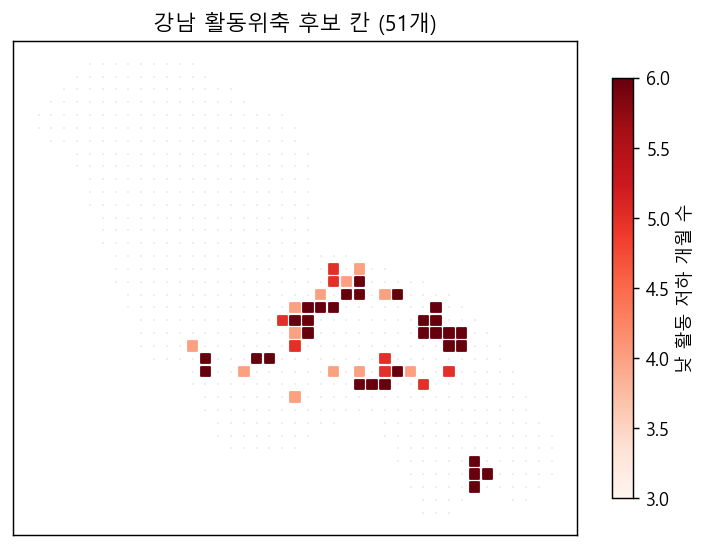

춘천 153 칸 | 제외 {'건물없음': 34, '비주거': 5} | 상위 동 [('신북읍', 65), ('서면', 32), ('사북면', 20), ('신동면', 14)]


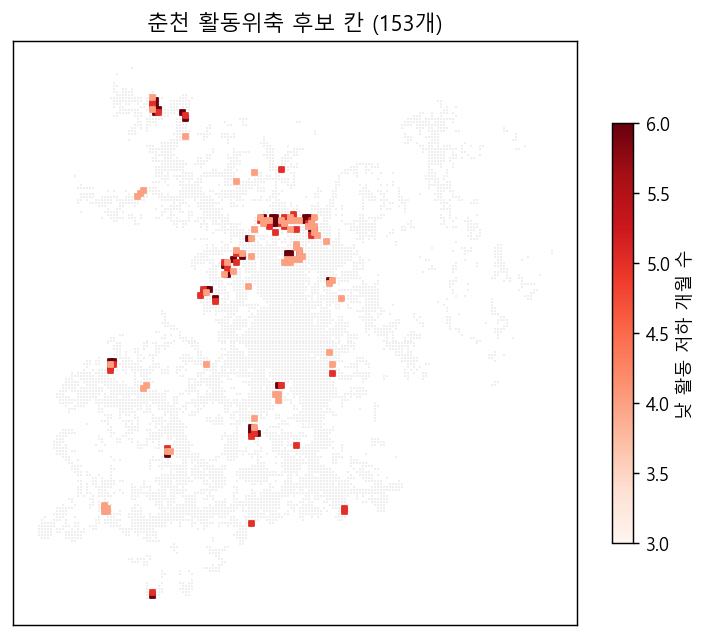

In [2]:
for reg in ['강남', '춘천']:
    r = core.find_candidates(reg)
    print(reg, r['result']['n_candidates'], '칸 | 제외', r['result']['dropped_status'], '| 상위 동', list(r['result']['by_emd'].items())[:4])
    display(Image(r['figures'][0], width=420))

## 2. 유형 분류: 2×2 고립 유형 + 원인·추천 표
교류 500m, 보건 3km 넘으면 '멂'

강남 {'연계형': 38, '긴급방문형': 13, '예방인프라형': 22, '관찰형': 453}


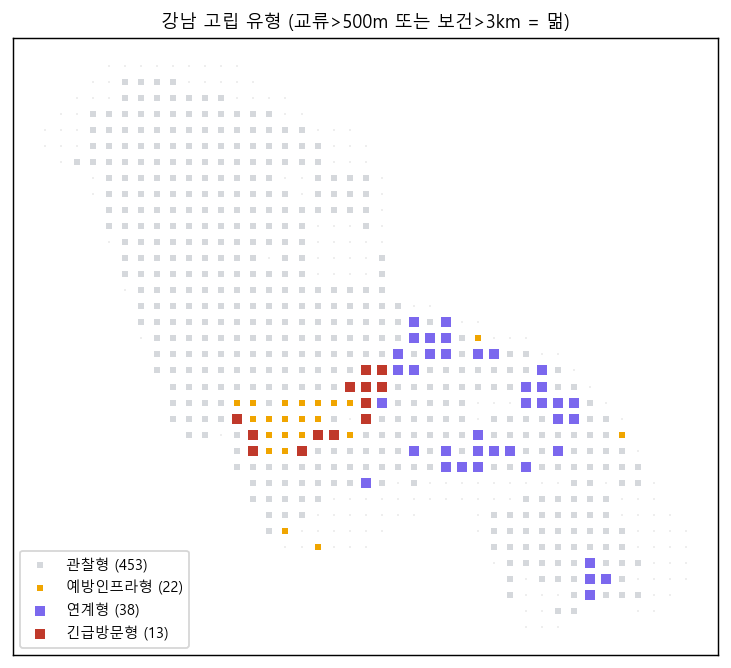

,emd_name,type,gap_tag,cause,recommendation
0,도곡2동,긴급방문형,보건,낮 활동 저하 6개월 / 60대+ 비중 27% / 교류 135m / 보건 3.8km,보건기관이 3.8km로 멂 → 방문 건강관리·이동형 상담
1,도곡2동,긴급방문형,보건,낮 활동 저하 6개월 / 60대+ 비중 27% / 교류 62m / 보건 3.6km,보건기관이 3.6km로 멂 → 방문 건강관리·이동형 상담
2,개포1동,긴급방문형,보건,낮 활동 저하 6개월 / 60대+ 비중 27% / 교류 132m / 보건 3.6km,보건기관이 3.6km로 멂 → 방문 건강관리·이동형 상담
3,개포2동,긴급방문형,보건,낮 활동 저하 6개월 / 60대+ 비중 26% / 교류 84m / 보건 3.3km,보건기관이 3.3km로 멂 → 방문 건강관리·이동형 상담
4,대치2동,긴급방문형,보건,낮 활동 저하 6개월 / 60대+ 비중 28% / 교류 245m / 보건 3.3km,보건기관이 3.3km로 멂 → 방문 건강관리·이동형 상담
5,개포2동,긴급방문형,보건,낮 활동 저하 6개월 / 60대+ 비중 30% / 교류 42m / 보건 3.0km,보건기관이 3.0km로 멂 → 방문 건강관리·이동형 상담


춘천 {'연계형': 98, '긴급방문형': 55, '예방인프라형': 101, '관찰형': 1361}


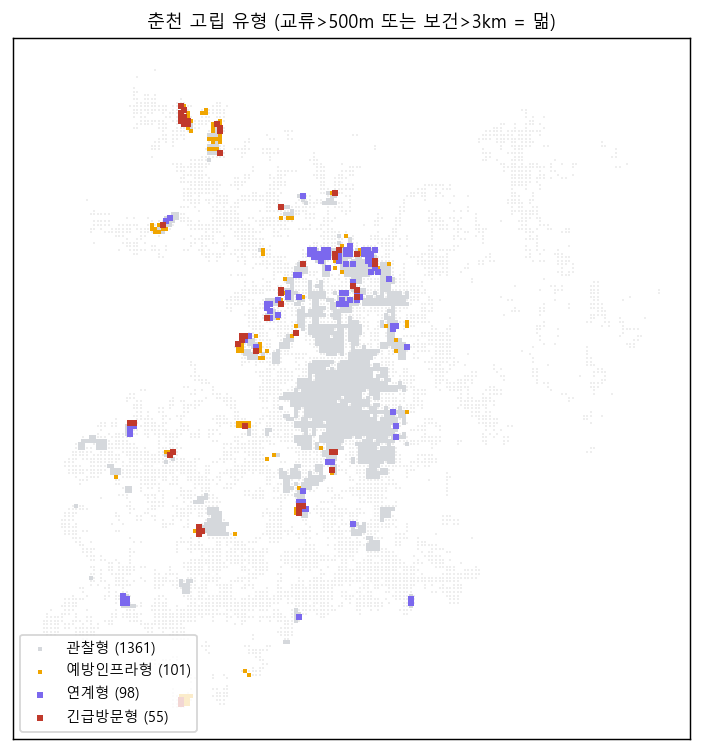

,emd_name,type,gap_tag,cause,recommendation
0,서면,긴급방문형,교류,낮 활동 저하 6개월 / 60대+ 비중 71% / 교류 620m / 보건 2.8km,교류시설이 620m로 멂 → 이동형 모임·안부 방문
1,서면,긴급방문형,교류,낮 활동 저하 6개월 / 60대+ 비중 70% / 교류 682m / 보건 2.9km,교류시설이 682m로 멂 → 이동형 모임·안부 방문
2,남면,긴급방문형,보건,낮 활동 저하 6개월 / 60대+ 비중 51% / 교류 413m / 보건 6.1km,보건기관이 6.1km로 멂 → 방문 건강관리·이동형 상담
3,사북면,긴급방문형,보건,낮 활동 저하 6개월 / 60대+ 비중 60% / 교류 321m / 보건 6.7km,보건기관이 6.7km로 멂 → 방문 건강관리·이동형 상담
4,사북면,긴급방문형,보건,낮 활동 저하 6개월 / 60대+ 비중 55% / 교류 377m / 보건 7.0km,보건기관이 7.0km로 멂 → 방문 건강관리·이동형 상담
5,사북면,긴급방문형,둘다,낮 활동 저하 6개월 / 60대+ 비중 57% / 교류 521m / 보건 7.2km,교류시설이 521m로 멂 → 이동형 모임·안부 방문 / 보건기관이 7.2km로 멂 → 방문 건강관리·이동형 상담


In [3]:
for reg in ['강남', '춘천']:
    r = core.classify(reg)
    print(reg, r['result']['type_counts'])
    display(Image(r['figures'][0], width=420))
    display(pd.DataFrame(r['result']['table'])[['emd_name','type','gap_tag','cause','recommendation']].head(6))

## 3. 배치 시뮬레이션: 이동형 거점 k곳 (긴급방문형 대상)

강남 반경 1000m 곡선 [(1, 73), (2, 100), (3, 100), (4, 100), (5, 100)]


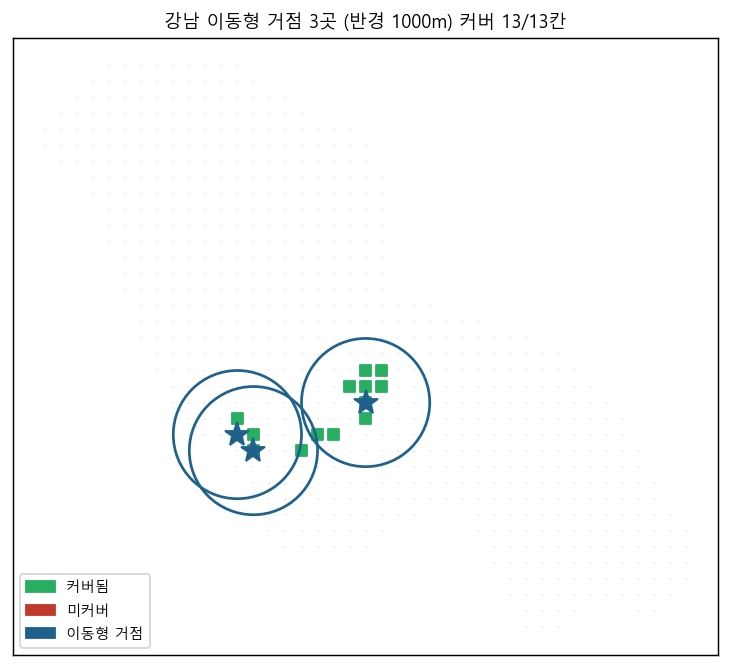

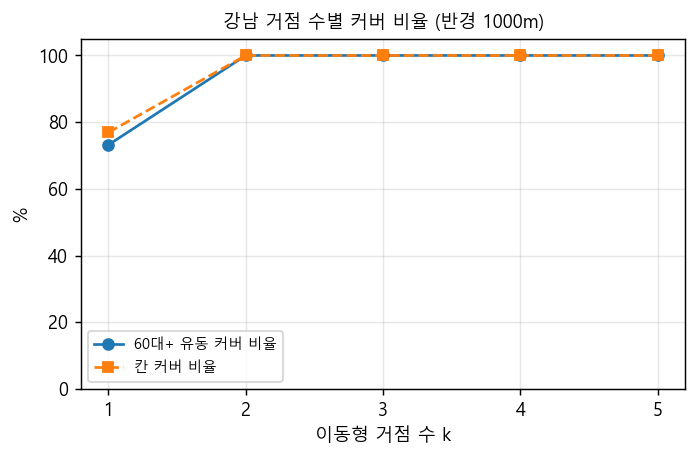

춘천 반경 1000m 곡선 [(1, 19), (2, 38), (3, 48), (4, 56), (5, 62)]


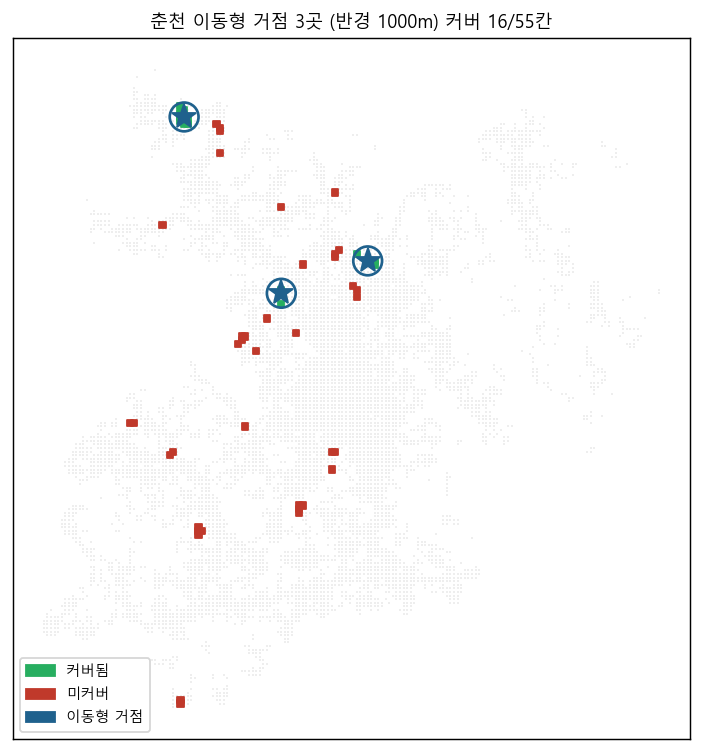

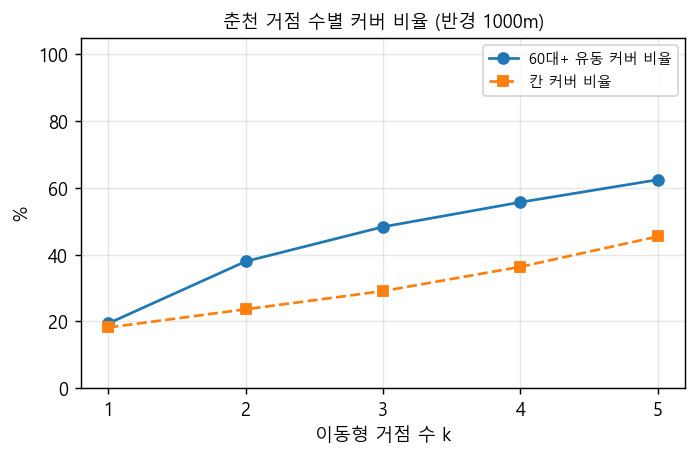

춘천 반경 3000m 곡선 [(1, 30), (2, 55), (3, 73), (4, 85), (5, 90)]


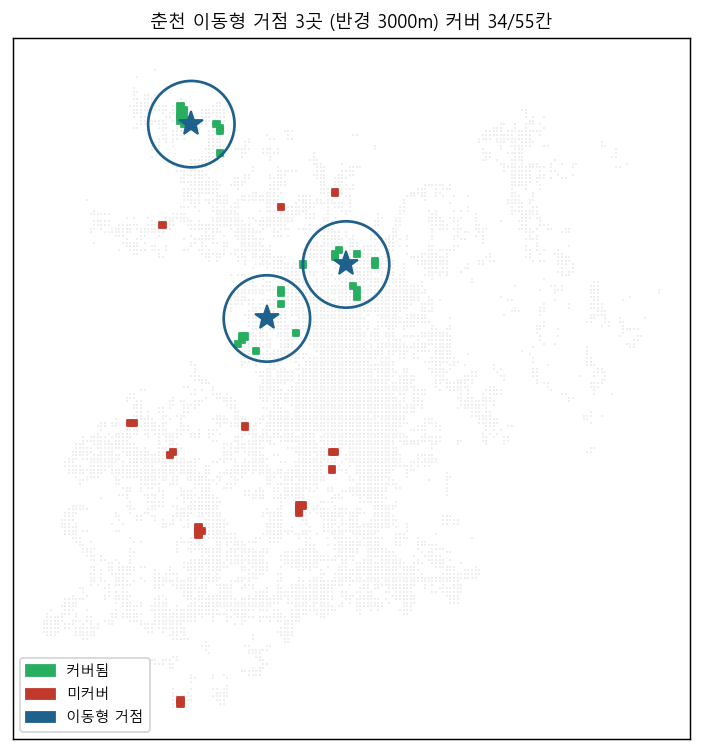

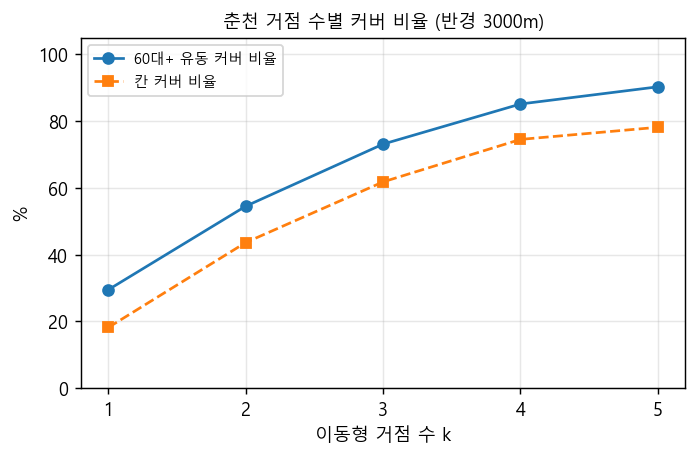

In [4]:
for reg, rad in [('강남', 1000), ('춘천', 1000), ('춘천', 3000)]:
    r = core.simulate_placement(reg, k=3, radius_m=rad)
    print(reg, f'반경 {rad}m', '곡선', [(c['k'], round(c['covered_senior_share']*100)) for c in r['result']['k_curve']])
    display(Image(r['figures'][0], width=380)); display(Image(r['figures'][1], width=420))

## 4. 강건성: 기준을 하나씩 바꿨을 때

In [5]:
for reg in ['강남', '춘천']:
    o = pd.DataFrame(core.robustness(reg)['result']['one_at_a_time'])
    print(reg); display(o[['param','value','연계형','긴급방문형','예방인프라형','urgent_retained']])

강남


,param,value,연계형,긴급방문형,예방인프라형,urgent_retained
0,persist_min,4,38,13,22,1.0000
1,persist_min,5,30,9,25,0.6923
2,persist_min,6,24,7,27,0.5385
3,far_social_m,300,33,18,29,1.0000
4,far_social_m,500,38,13,22,1.0000
5,far_social_m,1000,38,13,20,1.0000
6,far_health_m,2000,25,26,28,1.0000
7,far_health_m,3000,38,13,22,1.0000
8,far_health_m,5000,51,0,4,0.0000
9,residential_filter,False,50,15,26,1.0000


춘천


,param,value,연계형,긴급방문형,예방인프라형,urgent_retained
0,persist_min,4,98,55,101,1.0000
1,persist_min,5,51,34,119,0.6182
2,persist_min,6,27,18,135,0.3273
3,far_social_m,300,51,102,167,1.0000
4,far_social_m,500,98,55,101,1.0000
5,far_social_m,1000,136,17,52,0.3091
6,far_health_m,2000,81,72,131,1.0000
7,far_health_m,3000,98,55,101,1.0000
8,far_health_m,5000,98,55,92,1.0000
9,residential_filter,False,112,80,132,1.0000


## 5. 시설 변화 가정: 춘천 '지내2리 경로당'이 없어지면

In [6]:
r = core.facility_change('춘천', remove_ids=['CC_00225'])
print(r['result']['removed'], '| 바뀐 칸', r['result']['n_changed_cells'])
display(pd.DataFrame(r['result']['changed_cells']))

[{'fac_id': 'CC_00225', 'kind': '경로당', 'name': '지내2리 경로당'}] | 바뀐 칸 9


,cell_id,emd_name,before,after
0,4076_7982,신북읍,연계형,긴급방문형
1,4076_7983,신북읍,연계형,긴급방문형
2,4077_7981,신북읍,연계형,긴급방문형
3,4077_7982,신북읍,연계형,긴급방문형
4,4077_7983,신북읍,연계형,긴급방문형
5,4078_7980,신북읍,관찰형,예방인프라형
6,4078_7981,신북읍,연계형,긴급방문형
7,4078_7982,신북읍,연계형,긴급방문형
8,4078_7983,신북읍,관찰형,예방인프라형


## 6. 자원 조회(시민 모드) · 지역 맥락

In [7]:
r = core.lookup_resources('춘천', lat=37.8813, lon=127.7298, radius_m=1000)
display(pd.DataFrame(r['result']['nearest_by_kind']))
for reg in ['강남', '춘천']:
    c = core.region_context(reg)['result']
    print(reg, '로컬결제', c['local_payment_pct'], '| 60대+ 결제 시간대', c['senior60_card_time_pct'])

,kind,name,dist_m,addr,lat,lon
0,체육시설(공공),야외운동기구 소양동1,36.0,강원특별자치도 춘천시 공지로 591 (근화동),37.8812,127.7302
1,문화시설,춘천미술관,180.0,강원특별자치도 춘천시 서부대성로 71,37.8824,127.7313
2,경로당,미도파아파트 경로당,323.0,강원특별자치도 춘천시 금강로 68-9,37.8785,127.7286
3,도서관,춘천교육문화관,833.0,강원특별자치도 춘천시중앙로 107번길 14,37.8756,127.7236
4,보건,춘천시보건소,1057.0,강원특별자치도 춘천시 중앙로 135,37.8756,127.7202


강남 로컬결제 39.9 | 60대+ 결제 시간대 {'00_05': 2.76, '06_11': 27.1, '12_17': 51.16, '18_23': 18.99}
춘천 로컬결제 82.2 | 60대+ 결제 시간대 {'00_05': 1.2, '06_11': 27.28, '12_17': 53.66, '18_23': 17.85}
